In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Rows: 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

df.info()

display(df.describe())

print(df.columns.tolist())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:

print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nChurn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentages:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)


Duplicate rows: 0

Missing values per column:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Churn counts:


,count
Churn,
No,5174
Yes,1869



Churn percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [ ]:


print(df.dtypes)

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

blank_charges = df["TotalCharges"].astype(str).str.strip().eq("")

print("\nBlank TotalCharges values:", blank_charges.sum())

display(df.loc[blank_charges, ["customerID", "tenure", "TotalCharges", "Churn"]])


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

TotalCharges data type:
object

Blank TotalCharges values: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


In [ ]:

churn_counts = df["Churn"].value_counts()

print("Customer counts:")
display(churn_counts)

print("\nCustomer percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))


Customer counts:


,count
Churn,
No,5174
Yes,1869



Customer percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [ ]:

print("Total Customer IDs:", df["customerID"].count())


print("Unique Customer IDs:", df["customerID"].nunique())


print("Duplicate Customer IDs:", df["customerID"].duplicated().sum())

Total Customer IDs: 7043
Unique Customer IDs: 7043
Duplicate Customer IDs: 0


In [ ]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

Column: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Column: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: OnlineBack

In [ ]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

for col in numerical_columns:
    print(f"\nColumn: {col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Mean:", round(df[col].mean(), 2))
    print("Median:", df[col].median())


Column: SeniorCitizen
Minimum: 0
Maximum: 1
Mean: 0.16
Median: 0.0

Column: tenure
Minimum: 0
Maximum: 72
Mean: 32.37
Median: 29.0

Column: MonthlyCharges
Minimum: 18.25
Maximum: 118.75
Mean: 64.76
Median: 70.35


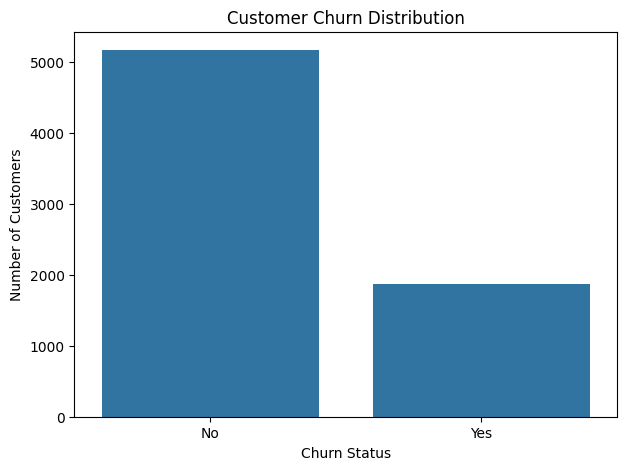

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

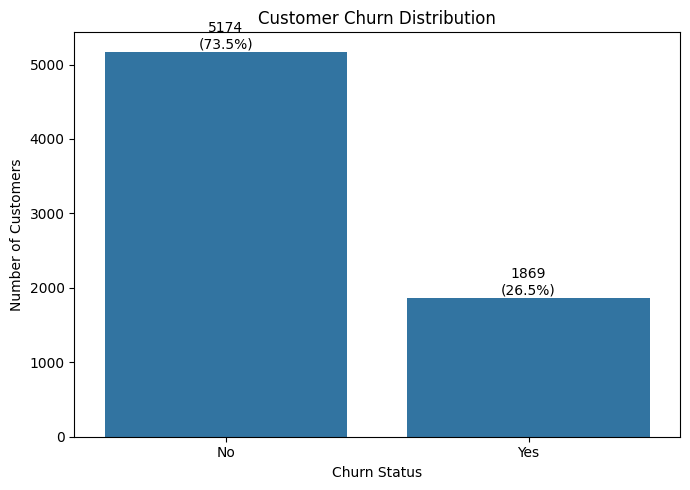

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x="Churn")

total = len(df)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = (count / total) * 100

    ax.annotate(
        f'{count}\n({percentage:.1f}%)',
        (bar.get_x() + bar.get_width() / 2, count),
        ha='center',
        va='bottom'
    )

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:

df["Churn_Encoded"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

contract_churn = df.groupby(
    "Contract"
)["Churn_Encoded"].mean() * 100

print("Churn Rate by Contract Type:")
display(contract_churn.round(2))

Churn Rate by Contract Type:


,Churn_Encoded
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


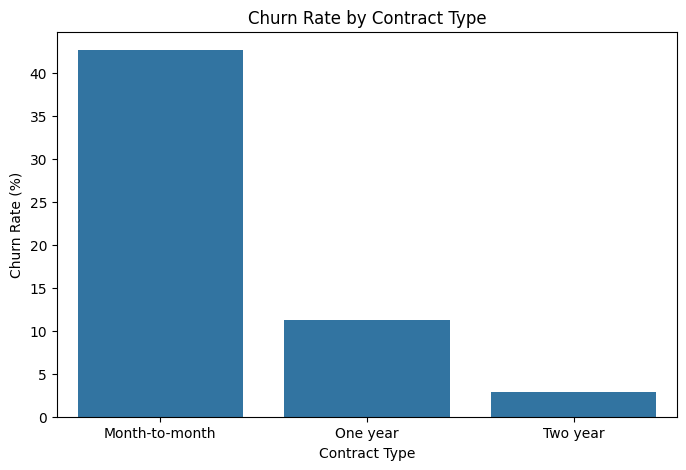

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

          Insight – Contract Type vs Customer Churn

The analysis reveals that month-to-month customers have the highest churn rate at 42.71%, followed by one-year contract customers at 11.27% and two-year contract customers at 2.83%. This indicates a strong association between contract duration and customer retention. The company should investigate retention strategies targeting month-to-month customers and explore incentives for longer-term contracts.


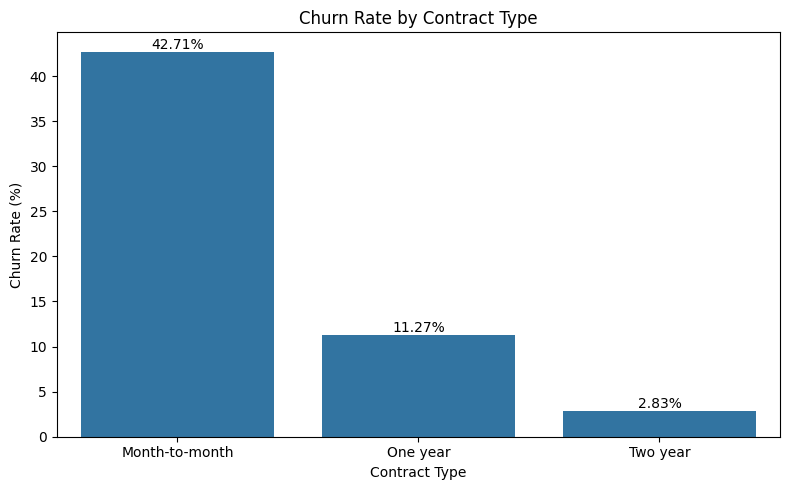

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width()/2, height),
        ha='center',
        va='bottom'
    )

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
tenure_analysis = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(tenure_analysis.round(2))


,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


Customers who churned generally had shorter relationships with the company than customers who stayed.

This suggests that the company should pay particular attention to new customers and improve their initial customer experience.

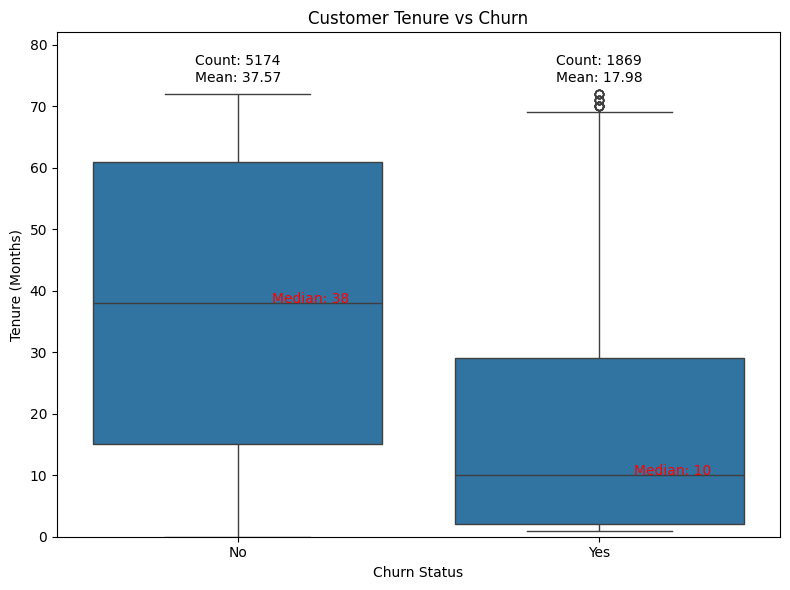

In [ ]:
plt.figure(figsize=(8, 6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

# Add numerical information
for i, churn_status in enumerate(["No", "Yes"]):

    data = df[df["Churn"] == churn_status]["tenure"]

    median = data.median()
    mean = data.mean()
    count = data.count()

    # Display median near the median line
    ax.annotate(
        f"Median: {median:.0f}",
        xy=(i, median),
        xytext=(25, 0),
        textcoords="offset points",
        color="red",
        fontsize=10
    )

    # Display count and mean above the boxplot
    ax.text(
        i, 74,
        f"Count: {count}\nMean: {mean:.2f}",
        ha="center",
        fontsize=10
    )

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.ylim(0, 82)

plt.tight_layout()
plt.show()

Customers who churned had an average tenure of 17.98 months, compared with 37.57 months for customers who stayed. The median tenure was 10 months for churned customers and 38 months for retained customers. This suggests that customers with shorter relationships are more vulnerable to churn, highlighting the importance of early customer engagement and retention strategies.

In [ ]:
monthly_analysis = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(monthly_analysis.round(2))

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


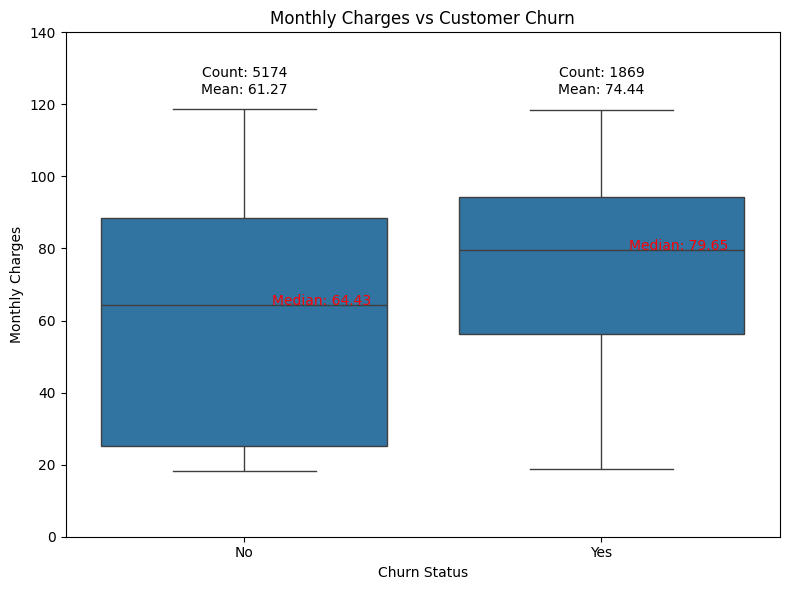

In [ ]:
plt.figure(figsize=(8, 6))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

for i, status in enumerate(["No", "Yes"]):

    data = df[df["Churn"] == status]["MonthlyCharges"]

    mean = data.mean()
    median = data.median()
    count = data.count()

    ax.text(
        i, 123,
        f"Count: {count}\nMean: {mean:.2f}",
        ha="center",
        fontsize=10
    )

    ax.annotate(
        f"Median: {median:.2f}",
        xy=(i, median),
        xytext=(20, 0),
        textcoords="offset points",
        color="red",
        fontsize=10
    )

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.ylim(0, 140)
plt.tight_layout()
plt.show()

In [ ]:
payment_churn = df.groupby(
    "PaymentMethod"
)["Churn_Encoded"].mean() * 100

print("Churn Rate by Payment Method:")
display(payment_churn.round(2))

Churn Rate by Payment Method:


,Churn_Encoded
PaymentMethod,
Bank transfer (automatic),16.71
Credit card (automatic),15.24
Electronic check,45.29
Mailed check,19.11


          Insight – Payment Method vs Customer Churn

Electronic check users have the highest churn rate at 45.29%, compared with 15.24% for automatic credit card payments, 16.71% for automatic bank transfers and 19.11% for mailed checks. This suggests an association between payment method and customer churn. The company should investigate the billing experience and payment preferences of electronic check users.

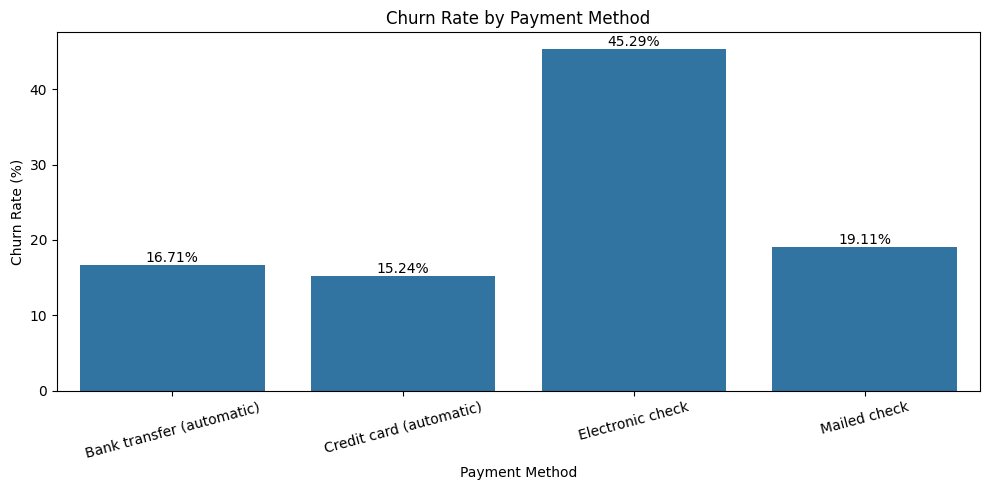

In [ ]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width()/2, height),
        ha='center',
        va='bottom'
    )

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
internet_churn = df.groupby(
    "InternetService"
)["Churn_Encoded"].mean() * 100

print("Churn Rate by Internet Service:")
display(internet_churn.round(2))

Churn Rate by Internet Service:


,Churn_Encoded
InternetService,
DSL,18.96
Fiber optic,41.89
No,7.40


     Insight – Internet Service vs Customer Churn

Fiber optic customers have the highest churn rate at 41.89%, followed by DSL customers at 18.96% and customers without internet service at 7.40%. This indicates a notable association between internet service type and customer churn. The company should investigate pricing, service quality and customer satisfaction among Fiber optic subscribers.


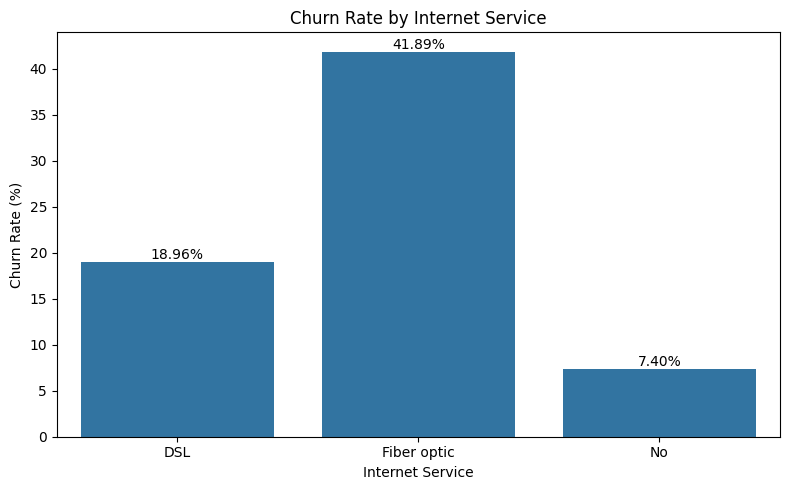

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width()/2, height),
        ha='center',
        va='bottom'
    )

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
security_churn = df.groupby(
    "OnlineSecurity"
)["Churn_Encoded"].mean() * 100

print("Churn Rate by Online Security:")
display(security_churn.round(2))

Churn Rate by Online Security:


,Churn_Encoded
OnlineSecurity,
No,41.77
No internet service,7.40
Yes,14.61


       Insight – Online Security vs Customer Churn

Customers without online security have the highest churn rate at 41.77%, compared with 14.61% among customers who subscribe to online security. Customers without internet service have a churn rate of 7.40%. This suggests an association between online security subscription status and customer retention. The company could investigate bundled security offerings and customer satisfaction to identify potential retention opportunities.

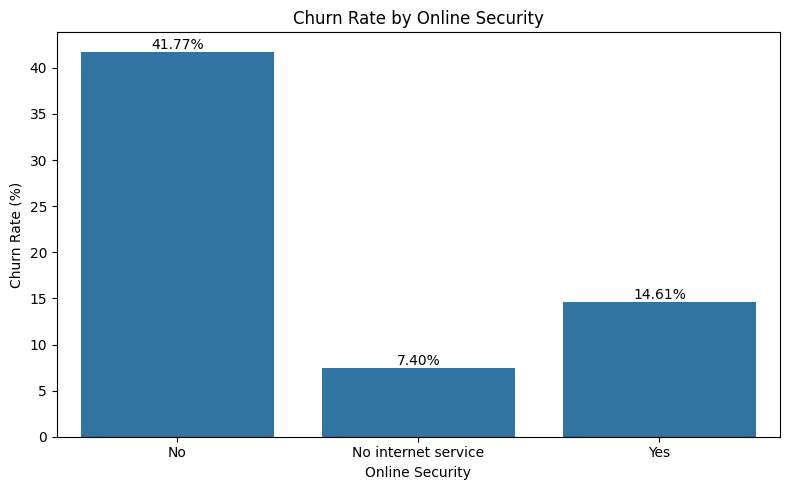

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=security_churn.index,
    y=security_churn.values
)

for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f'{height:.2f}%',
        (bar.get_x() + bar.get_width()/2, height),
        ha='center',
        va='bottom'
    )

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
support_churn = df.groupby(
    "TechSupport"
)["Churn_Encoded"].mean() * 100

print("Churn Rate by Tech Support:")
display(support_churn.round(2))

Churn Rate by Tech Support:


,Churn_Encoded
TechSupport,
No,41.64
No internet service,7.40
Yes,15.17


      Insight – Tech Support vs Customer Churn

Customers without technical support have the highest churn rate at 41.64%, compared with 15.17% among customers who subscribe to technical support. Customers without internet service have a churn rate of 7.40%. This indicates an association between technical support subscription status and customer retention. The company should investigate support accessibility, service quality and customer satisfaction to identify potential retention improvements.

In [ ]:
# Create a separate copy for cleaning
df_clean = df.copy()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values
print("Missing values after conversion:")

display(
    df_clean.isnull().sum().sort_values(
        ascending=False
    )
)

Missing values after conversion:


,0
TotalCharges,11
customerID,0
SeniorCitizen,0
Partner,0
Dependents,0
gender,0
tenure,0
PhoneService,0
InternetService,0
MultipleLines,0


In [ ]:
# Display customers with missing TotalCharges

missing_customers = df_clean[
    df_clean["TotalCharges"].isnull()
]

display(
    missing_customers[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Contract", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


In [ ]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print("Missing values after treatment:",
      df_clean["TotalCharges"].isnull().sum())

print("TotalCharges data type:",
      df_clean["TotalCharges"].dtype)

Missing values after treatment: 0
TotalCharges data type: float64


In [ ]:
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nData Types:")
print(df_clean.dtypes)

Dataset Shape: (7043, 22)

Missing Values:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
Churn_Encoded         int64
dtype: object


In [ ]:
categorical_columns = df_clean.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].unique())


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

Churn:
['No' 'Yes']


In [ ]:
for col in df_clean.select_dtypes(include="object").columns:
    spaces = df_clean[col].astype(str).str.strip().ne(
        df_clean[col].astype(str)
    ).sum()

    if spaces > 0:
        print(col, spaces)

In [ ]:
df_clean = df_clean.drop(columns=["customerID"])

print("Updated Dataset Shape:", df_clean.shape)
print(df_clean.columns.tolist())

Updated Dataset Shape: (7043, 21)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Encoded']


In [ ]:
df_clean = df_clean.drop(columns=["Churn_Encoded"])

print("Updated Dataset Shape:", df_clean.shape)
print(df_clean.columns.tolist())

Updated Dataset Shape: (7043, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

print("\nNumerical Count:", len(numerical_features))
print("Categorical Count:", len(categorical_features))

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Count: 4
Categorical Count: 15


In [ ]:
for col in categorical_features:
    print(f"{col}: {X[col].nunique()} unique categories")

gender: 2 unique categories
Partner: 2 unique categories
Dependents: 2 unique categories
PhoneService: 2 unique categories
MultipleLines: 3 unique categories
InternetService: 3 unique categories
OnlineSecurity: 3 unique categories
OnlineBackup: 3 unique categories
DeviceProtection: 3 unique categories
TechSupport: 3 unique categories
StreamingTV: 3 unique categories
StreamingMovies: 3 unique categories
Contract: 3 unique categories
PaperlessBilling: 2 unique categories
PaymentMethod: 4 unique categories


In [ ]:
binary_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling"
]

for col in binary_features:
    print(f"\n{col}:")
    print(X[col].value_counts())


gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64


In [ ]:
# Make a fresh copy of the features
X_encoded = X.copy()

# Convert binary categories to 0/1
binary_mappings = {
    "gender": {"Female": 0, "Male": 1},
    "Partner": {"No": 0, "Yes": 1},
    "Dependents": {"No": 0, "Yes": 1},
    "PhoneService": {"No": 0, "Yes": 1},
    "PaperlessBilling": {"No": 0, "Yes": 1},
}

X_encoded = X_encoded.replace(binary_mappings)

# One-hot encode the remaining categorical features
X_encoded = pd.get_dummies(
    X_encoded,
    columns=[col for col in categorical_features if col not in binary_features],
    dtype=int
)

# Encode the target: No = 0, Yes = 1
y_encoded = y.map({"No": 0, "Yes": 1})

print("Encoded features shape:", X_encoded.shape)
print("Encoded target shape:", y_encoded.shape)
print("Any missing values in features:", X_encoded.isnull().sum().sum())
print("Target mapping:", y_encoded.value_counts().to_dict())

Encoded features shape: (7043, 40)
Encoded target shape: (7043,)
Any missing values in features: 0
Target mapping: {0: 5174, 1: 1869}


/tmp/ipykernel_5001/204202491.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_encoded = X_encoded.replace(binary_mappings)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training features: (5634, 40)
Testing features: (1409, 40)
Training churn rate: 26.54 %
Testing churn rate: 26.54 %


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


scale_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_columns] = scaler.fit_transform(
    X_train[scale_columns]
)

X_test_scaled[scale_columns] = scaler.transform(
    X_test[scale_columns]
)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 80.55 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[926 109]
 [165 209]]


In [ ]:
from sklearn.metrics import classification_report

churn_probabilities = model.predict_proba(X_test_scaled)[:, 1]

y_pred_40 = (churn_probabilities >= 0.40).astype(int)

print(classification_report(y_test, y_pred_40))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [ ]:
from sklearn.metrics import confusion_matrix

print("Default threshold (0.50):")
print(confusion_matrix(y_test, y_pred))

print("\nLower threshold (0.40):")
print(confusion_matrix(y_test, y_pred_40))

Default threshold (0.50):
[[926 109]
 [165 209]]

Lower threshold (0.40):
[[845 190]
 [124 250]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 77.93 %

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1035
           1       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_rf))

[[919 116]
 [195 179]]


In [ ]:
import pandas as pd

coefficients = pd.Series(
    model.coef_[0],
    index=X_train_scaled.columns
)

print("Largest positive coefficients (associated with higher churn odds):")
print(coefficients.sort_values(ascending=False).head(10))

print("\nLargest negative coefficients (associated with lower churn odds):")
print(coefficients.sort_values().head(10))

Largest positive coefficients (associated with higher churn odds):
InternetService_Fiber optic       0.594133
Contract_Month-to-month           0.529294
TotalCharges                      0.520075
PaperlessBilling                  0.370498
PaymentMethod_Electronic check    0.162455
StreamingTV_Yes                   0.156571
StreamingMovies_Yes               0.156527
SeniorCitizen                     0.145907
OnlineSecurity_No                 0.109713
MultipleLines_Yes                 0.106067
dtype: float64

Largest negative coefficients (associated with lower churn odds):
tenure                                 -1.243783
Contract_Two year                      -0.815464
InternetService_DSL                    -0.701492
MonthlyCharges                         -0.599561
TechSupport_No internet service        -0.349469
DeviceProtection_No internet service   -0.349469
OnlineBackup_No internet service       -0.349469
InternetService_No                     -0.349469
StreamingMovies_No internet s

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

churn_probabilities = model.predict_proba(X_test_scaled)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60]:
    y_pred_threshold = (churn_probabilities >= threshold).astype(int)

    print(
        f"Threshold {threshold:.2f} | "
        f"Precision: {precision_score(y_test, y_pred_threshold):.2f} | "
        f"Recall: {recall_score(y_test, y_pred_threshold):.2f} | "
        f"F1: {f1_score(y_test, y_pred_threshold):.2f}"
    )

Threshold 0.30 | Precision: 0.52 | Recall: 0.75 | F1: 0.62
Threshold 0.40 | Precision: 0.57 | Recall: 0.67 | F1: 0.61
Threshold 0.50 | Precision: 0.66 | Recall: 0.56 | F1: 0.60
Threshold 0.60 | Precision: 0.72 | Recall: 0.40 | F1: 0.51


In [ ]:
from sklearn.model_selection import train_test_split

X_train2, X_val, y_train2, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train2.shape)
print("Validation set:", X_val.shape)
print("Validation churn rate:", round(y_val.mean() * 100, 2), "%")


Training subset: (4507, 40)
Validation set: (1127, 40)
Validation churn rate: 26.53 %


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

scale_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler_val = StandardScaler()

X_train2_scaled = X_train2.copy()
X_val_scaled = X_val.copy()

X_train2_scaled[scale_columns] = scaler_val.fit_transform(
    X_train2[scale_columns]
)

X_val_scaled[scale_columns] = scaler_val.transform(
    X_val[scale_columns]
)

model_val = LogisticRegression(max_iter=1000, random_state=42)
model_val.fit(X_train2_scaled, y_train2)

val_probabilities = model_val.predict_proba(X_val_scaled)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60]:
    val_pred = (val_probabilities >= threshold).astype(int)

    print(
        f"Threshold {threshold:.2f} | "
        f"Precision: {precision_score(y_val, val_pred):.2f} | "
        f"Recall: {recall_score(y_val, val_pred):.2f} | "
        f"F1: {f1_score(y_val, val_pred):.2f}"
    )

Threshold 0.30 | Precision: 0.54 | Recall: 0.76 | F1: 0.63
Threshold 0.40 | Precision: 0.62 | Recall: 0.67 | F1: 0.64
Threshold 0.50 | Precision: 0.70 | Recall: 0.55 | F1: 0.61
Threshold 0.60 | Precision: 0.73 | Recall: 0.37 | F1: 0.49


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

scale_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

final_scaler = StandardScaler()
X_train_final = X_train.copy()
X_test_final = X_test.copy()

X_train_final[scale_columns] = final_scaler.fit_transform(X_train[scale_columns])
X_test_final[scale_columns] = final_scaler.transform(X_test[scale_columns])

final_model = LogisticRegression(max_iter=1000, random_state=42)
final_model.fit(X_train_final, y_train)

test_probabilities = final_model.predict_proba(X_test_final)[:, 1]
y_test_pred_final = (test_probabilities >= 0.40).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_test_pred_final) * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, y_test_pred_final))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

Accuracy: 77.71 %

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion matrix:
[[845 190]
 [124 250]]


                   Model Evaluation

I used Logistic Regression to predict which customers are likely to leave. After comparing thresholds on the validation set, I chose **0.40** and evaluated the model on the test set.

The model achieved **77.71% accuracy**. It correctly identified **250 of the 374 customers who churned**, but missed 124. Of the customers it flagged as likely to churn, **57% actually churned**.

Using a 0.40 threshold helped the model catch more churners than the default 0.50 threshold, though it also flagged more customers who stayed. This trade-off matters: the business needs to balance the cost of missing a customer who may leave against the cost of contacting someone who would have stayed.


we can recommend:
- Review the customer experience and pricing for fiber-optic customers, who showed higher churn in this dataset.
- Consider retention offers or contract incentives for month-to-month customers.
- Offer proactive support to customers with shorter tenure.
- Investigate why customers using electronic checks had higher churn.

In [ ]:
%pip install -q lightgbm shap

In [ ]:
import lightgbm
import shap

print("LightGBM:", lightgbm.__version__)
print("SHAP:", shap.__version__)


LightGBM: 4.6.0
SHAP: 0.54.1


In [ ]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

lgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

lgbm_probabilities = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_predictions = (lgbm_probabilities >= 0.40).astype(int)

print("Accuracy:", round(accuracy_score(y_test, lgbm_predictions) * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, lgbm_predictions, target_names=["No Churn", "Churn"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, lgbm_predictions))

Accuracy: 73.39 %

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.71      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409

Confusion matrix:
[[739 296]
 [ 79 295]]


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


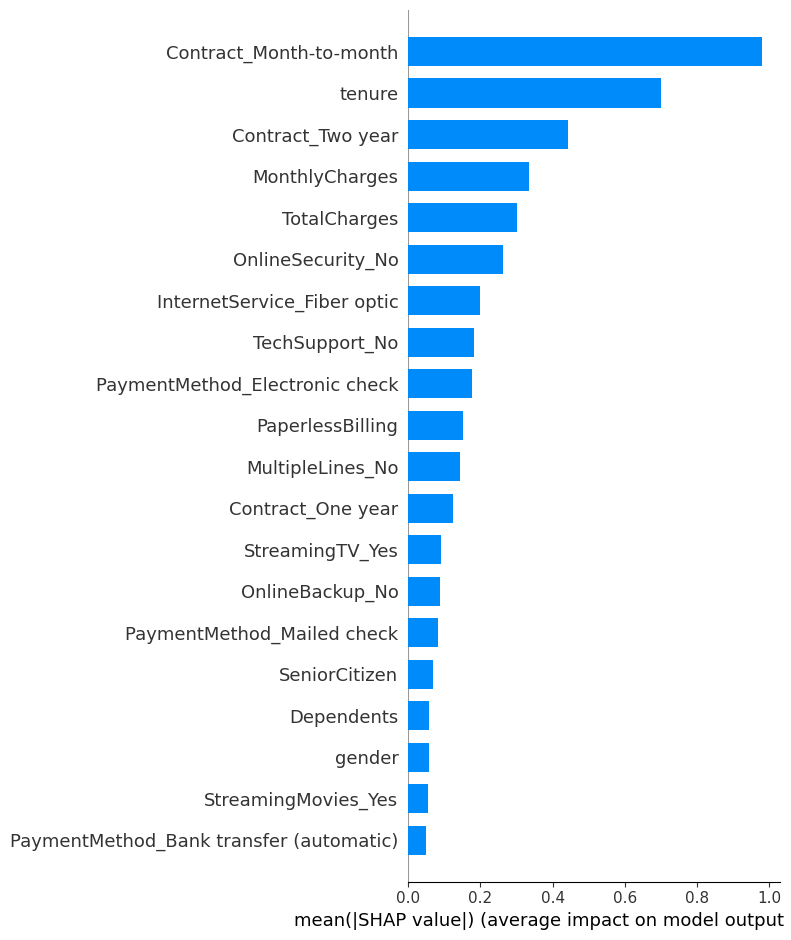

In [ ]:
import shap
import matplotlib.pyplot as plt
X_shap = X_test.sample(n=min(500, len(X_test)), random_state=42)

explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, X_shap, plot_type="bar")

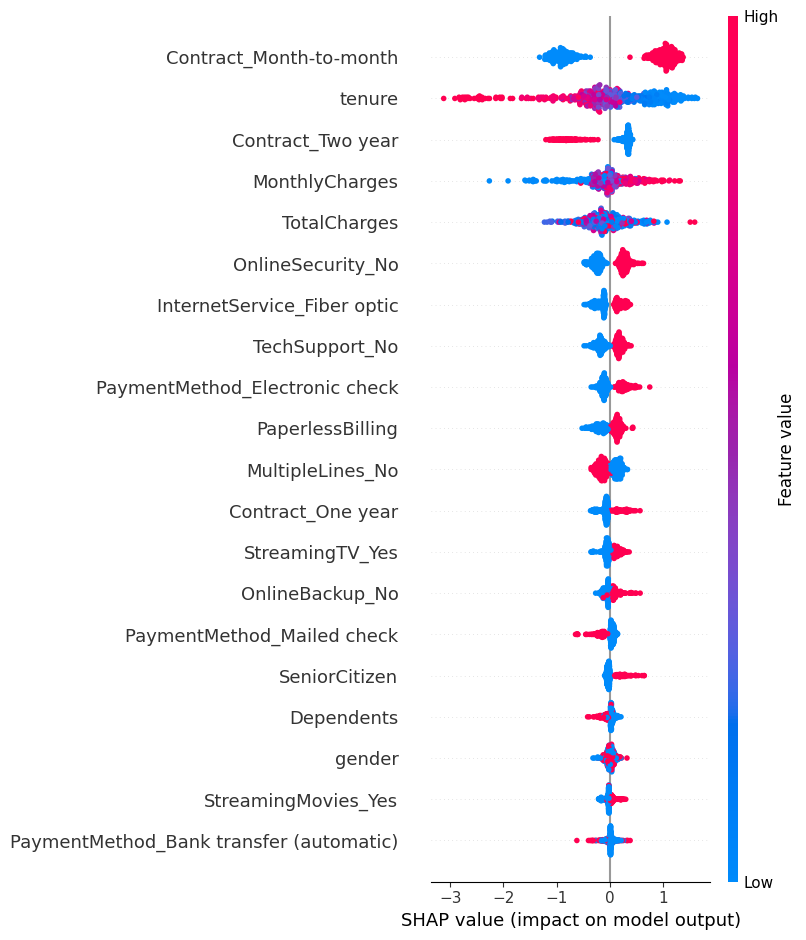

In [ ]:
shap.summary_plot(shap_values, X_shap)

In [ ]:
import pandas as pd
import numpy as np

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean absolute SHAP value": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean absolute SHAP value", ascending=False)

shap_importance.head(10).round(4)

,Feature,Mean absolute SHAP value
33,Contract_Month-to-month,0.9806
4,tenure,0.6989
35,Contract_Two year,0.4413
7,MonthlyCharges,0.3350
8,TotalCharges,0.3010
15,OnlineSecurity_No,0.2629
13,InternetService_Fiber optic,0.1989
24,TechSupport_No,0.1815
38,PaymentMethod_Electronic check,0.1757
6,PaperlessBilling,0.1518


In [ ]:
df_segments = df_clean.copy()

df_segments["TenureSegment"] = pd.cut(
    df_segments["tenure"],
    bins=[-1, 12, 48, 72],
    labels=["New (0–12 months)", "Established (13–48 months)", "Long-term (49–72 months)"]
)

segment_summary = (
    df_segments.groupby("TenureSegment", observed=False)
    .agg(
        Customers=("Churn", "size"),
        Churned=("Churn", lambda s: (s == "Yes").sum()),
        ChurnRate=("Churn", lambda s: (s == "Yes").mean() * 100)
    )
    .reset_index()
)

segment_summary["ChurnRate"] = segment_summary["ChurnRate"].round(2)
segment_summary

,TenureSegment,Customers,Churned,ChurnRate
0,New (0–12 months),2186,1037,47.44
1,Established (13–48 months),2618,619,23.64
2,Long-term (49–72 months),2239,213,9.51


In [ ]:
contract_summary = (
    df_clean.groupby("Contract")
    .agg(
        Customers=("Churn", "size"),
        Churned=("Churn", lambda s: (s == "Yes").sum()),
        ChurnRate=("Churn", lambda s: (s == "Yes").mean() * 100)
    )
    .reset_index()
)

contract_summary["ChurnRate"] = contract_summary["ChurnRate"].round(2)
contract_summary.sort_values("ChurnRate", ascending=False)

,Contract,Customers,Churned,ChurnRate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [ ]:
import pandas as pd
[name for name, obj in globals().items() if isinstance(obj, pd.DataFrame)]

['_',
 '__',
 '___',
 'df',
 '_2',
 'tenure_analysis',
 'monthly_analysis',
 'df_clean',
 'missing_customers',
 'X',
 'X_encoded',
 'X_train',
 'X_test',
 'X_train_scaled',
 'X_test_scaled',
 'X_train2',
 'X_val',
 'X_train2_scaled',
 'X_val_scaled',
 'X_train_final',
 'X_test_final',
 'X_shap',
 'shap_importance',
 '_56',
 'df_segments',
 'segment_summary',
 '_57',
 'contract_summary',
 '_58']

In [ ]:
print(df_clean.columns.tolist())
display(df_clean.head(3))

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [ ]:
df_clv = df_clean.copy()

print("df_clv created:", df_clv.shape)
display(df_clv.head())

df_clv created: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(df_clv.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
# Create CLV fields expected by the segmentation cell
df_clv = df_clean.copy()

df_clv["TotalCharges"] = pd.to_numeric(df_clv["TotalCharges"], errors="coerce")
df_clv["TenureSegment"] = pd.cut(
    df_clv["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0–12 months", "13–24 months", "25–48 months", "49+ months"]
)

df_clv["EstimatedHistoricalRevenue"] = df_clv["TotalCharges"]

print(df_clv[["tenure", "TotalCharges", "TenureSegment", "EstimatedHistoricalRevenue"]].head())

   tenure  TotalCharges TenureSegment  EstimatedHistoricalRevenue
0       1         29.85   0–12 months                       29.85
1      34       1889.50  25–48 months                     1889.50
2       2        108.15   0–12 months                      108.15
3      45       1840.75  25–48 months                     1840.75
4       2        151.65   0–12 months                      151.65


In [ ]:

segment_clv = (
    df_clv.groupby("TenureSegment", observed=False)
    .agg(
        Customers=("tenure", "size"),
        AverageHistoricalRevenue=("EstimatedHistoricalRevenue", "mean"),
        TotalHistoricalRevenue=("EstimatedHistoricalRevenue", "sum")
    )
    .round(2)
    .reset_index()
)

segment_clv

,TenureSegment,Customers,AverageHistoricalRevenue,TotalHistoricalRevenue
0,0–12 months,2186,275.23,601651.90
1,13–24 months,1024,1126.26,1153287.70
2,25–48 months,1594,2390.45,3810380.35
3,49+ months,2239,4685.51,10490848.75


In [ ]:
segment_churn = (
    df_clv.groupby("TenureSegment", observed=False)
    .agg(
        Customers=("tenure", "size"),
        Churned=("Churn", lambda s: (s == "Yes").sum()),
        ChurnRate=("Churn", lambda s: (s == "Yes").mean() * 100)
    )
    .round(2)
    .reset_index()
)
churn_clv = (
    df_clv.groupby("Churn")
    .agg(
        Customers=("tenure", "size"),
        AverageHistoricalRevenue=("EstimatedHistoricalRevenue", "mean")
    )
    .round(2)
    .reset_index()
)

segment_churn, churn_clv

(  TenureSegment  Customers  Churned  ChurnRate
 0   0–12 months       2186     1037      47.44
 1  13–24 months       1024      294      28.71
 2  25–48 months       1594      325      20.39
 3    49+ months       2239      213       9.51,
   Churn  Customers  AverageHistoricalRevenue
 0    No       5174                   2549.91
 1   Yes       1869                   1531.80)

In [ ]:
overall_churn_rate = (df_clv["Churn"].eq("Yes").mean() * 100).round(2)

avg_revenue_no = df_clv.loc[
    df_clv["Churn"] == "No", "EstimatedHistoricalRevenue"
].mean()

avg_revenue_yes = df_clv.loc[
    df_clv["Churn"] == "Yes", "EstimatedHistoricalRevenue"
].mean()

revenue_difference = (avg_revenue_no - avg_revenue_yes).round(2)

print(f"Overall churn rate: {overall_churn_rate}%")
print(f"Average historical revenue difference (retained - churned): {revenue_difference}")

Overall churn rate: 26.54%
Average historical revenue difference (retained - churned): 1018.12


In [ ]:
%pip install -q lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import lifelines
from lifelines import KaplanMeierFitter

print("Lifelines:", lifelines.__version__)
df_survival = df_clean[["tenure", "Churn"]].copy()
df_survival["event"] = (df_survival["Churn"] == "Yes").astype(int)

print("Rows:", len(df_survival))
print("Churn events:", df_survival["event"].sum())
print("Censored (not churned):", (df_survival["event"] == 0).sum())
df_survival.head()

Lifelines: 0.30.3
Rows: 7043
Churn events: 1869
Censored (not churned): 5174


,tenure,Churn,event
0,1,No,0
1,34,No,0
2,2,Yes,1
3,45,No,0
4,2,Yes,1


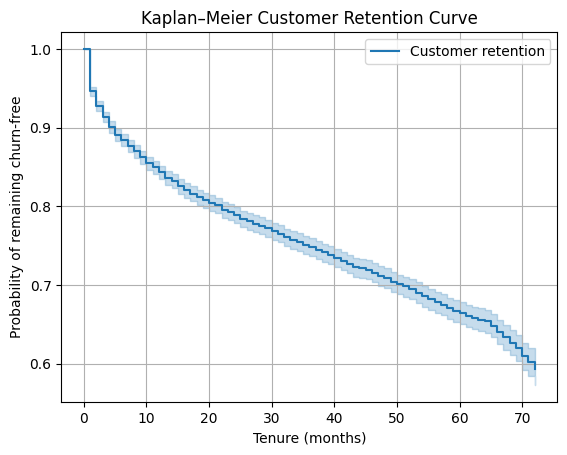

Estimated churn-free probability at 12 months: 84.32 %
Estimated churn-free probability at 24 months: 78.87 %


In [ ]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
kmf.fit(
    durations=df_survival["tenure"],
    event_observed=df_survival["event"],
    label="Customer retention"
)

kmf.plot_survival_function()
plt.title("Kaplan–Meier Customer Retention Curve")
plt.xlabel("Tenure (months)")
plt.ylabel("Probability of remaining churn-free")
plt.grid(True)
plt.show()

print("Estimated churn-free probability at 12 months:",
      round(kmf.predict(12) * 100, 2), "%")
print("Estimated churn-free probability at 24 months:",
      round(kmf.predict(24) * 100, 2), "%")

In [ ]:
print("Churn-free probability at 12 months:",
      round(kmf.predict(12) * 100, 2), "%")
print("Churn-free probability at 24 months:",
      round(kmf.predict(24) * 100, 2), "%")

Churn-free probability at 12 months: 84.32 %
Churn-free probability at 24 months: 78.87 %


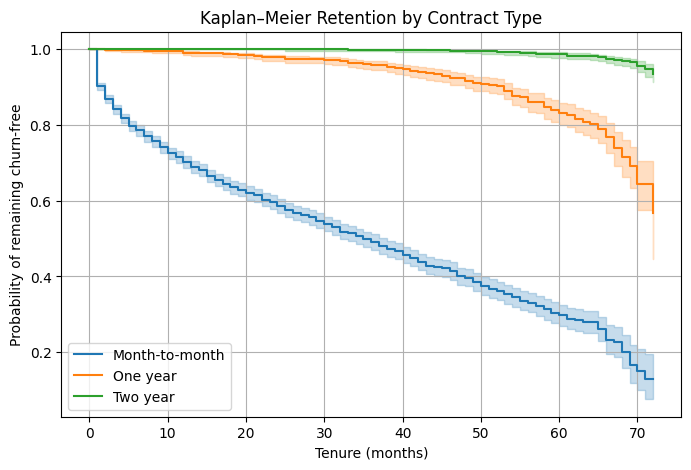

In [ ]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for contract in df_clean["Contract"].unique():
    mask = df_clean["Contract"] == contract
    kmf_contract = KaplanMeierFitter()
    kmf_contract.fit(
        durations=df_clean.loc[mask, "tenure"],
        event_observed=(df_clean.loc[mask, "Churn"] == "Yes").astype(int),
        label=contract
    )
    kmf_contract.plot_survival_function()

plt.title("Kaplan–Meier Retention by Contract Type")
plt.xlabel("Tenure (months)")
plt.ylabel("Probability of remaining churn-free")
plt.grid(True)
plt.show()

In [ ]:
for contract in df_clean["Contract"].unique():
    mask = df_clean["Contract"] == contract
    kmf_contract = KaplanMeierFitter()
    kmf_contract.fit(
        durations=df_clean.loc[mask, "tenure"],
        event_observed=(df_clean.loc[mask, "Churn"] == "Yes").astype(int)
    )
    print(f"{contract}: {kmf_contract.predict(12) * 100:.2f}%")

Month-to-month: 70.31%
One year: 99.08%
Two year: 100.00%


In [ ]:
from lifelines.statistics import multivariate_logrank_test

logrank = multivariate_logrank_test(
    df_clean["tenure"],
    df_clean["Contract"],
    event_observed=(df_clean["Churn"] == "Yes").astype(int)
)

print("Log-rank test statistic:", round(logrank.test_statistic, 4))
print("p-value:", logrank.p_value)

Log-rank test statistic: 2352.8725
p-value: 0.0


In [ ]:
contract_retention = (
    df_clean.groupby("Contract")
    .agg(
        Customers=("tenure", "size"),
        Churned=("Churn", lambda s: (s == "Yes").sum()),
        ChurnRate=("Churn", lambda s: (s == "Yes").mean() * 100)
    )
    .round(2)
    .reset_index()
    .sort_values("ChurnRate", ascending=False)
)

contract_retention

,Contract,Customers,Churned,ChurnRate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [ ]:
contract_retention.to_csv("contract_retention_summary.csv", index=False)
print("Saved: contract_retention_summary.csv")

Saved: contract_retention_summary.csv


In [ ]:
clv_summary = (
    df_clv.groupby("Churn")
    .agg(
        Customers=("tenure", "size"),
        AverageTenure=("tenure", "mean"),
        AverageMonthlyCharges=("MonthlyCharges", "mean"),
        AverageHistoricalRevenue=("EstimatedHistoricalRevenue", "mean")
    )
    .round(2)
    .reset_index()
)

clv_summary

,Churn,Customers,AverageTenure,AverageMonthlyCharges,AverageHistoricalRevenue
0,No,5174,37.57,61.27,2549.91
1,Yes,1869,17.98,74.44,1531.80


In [ ]:
import pandas as pd

# 1. Define df_clv since it was missing in the notebook state
df_clv = df_segments.copy()
df_clv["EstimatedHistoricalRevenue"] = df_clv["tenure"] * df_clv["MonthlyCharges"]

# 2. Re-create clv_summary successfully
clv_summary = (
    df_clv.groupby("Churn")
    .agg(
        Customers=("tenure", "size"),
        AverageTenure=("tenure", "mean"),
        AverageMonthlyCharges=("MonthlyCharges", "mean"),
        AverageHistoricalRevenue=("EstimatedHistoricalRevenue", "mean")
    )
    .round(2)
    .reset_index()
)

# 3. Save the summary to a CSV file
clv_summary.to_csv("clv_summary.csv", index=False)
print("Saved: clv_summary.csv")
clv_summary

Saved: clv_summary.csv


,Churn,Customers,AverageTenure,AverageMonthlyCharges,AverageHistoricalRevenue
0,No,5174,37.57,61.27,2549.77
1,Yes,1869,17.98,74.44,1531.61


In [ ]:
%pip install -q causalml

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from importlib.metadata import version, PackageNotFoundError

try:
    print("CausalML:", version("causalml"))
except PackageNotFoundError:
    print("CausalML package not found")

CausalML: 0.18.0


In [ ]:
customers_targeted = 1000
assumed_churn_reduction = 0.05
retention_campaign_cost_per_customer = 10
average_monthly_charge = df_clean["MonthlyCharges"].mean()
assumed_months_retained = 6
customers_retained = customers_targeted * assumed_churn_reduction
revenue_preserved = customers_retained * average_monthly_charge * assumed_months_retained
campaign_cost = customers_targeted * retention_campaign_cost_per_customer
estimated_net_benefit = revenue_preserved - campaign_cost
estimated_roi_percent = (estimated_net_benefit / campaign_cost) * 100

print(f"Customers targeted: {customers_targeted}")
print(f"Assumed additional customers retained: {customers_retained:.0f}")
print(f"Estimated revenue preserved: {revenue_preserved:.2f}")
print(f"Campaign cost: {campaign_cost:.2f}")
print(f"Estimated net benefit: {estimated_net_benefit:.2f}")
print(f"Scenario ROI: {estimated_roi_percent:.2f}%")

Customers targeted: 1000
Assumed additional customers retained: 50
Estimated revenue preserved: 19428.51
Campaign cost: 10000.00
Estimated net benefit: 9428.51
Scenario ROI: 94.29%


In [ ]:
roi_summary = pd.DataFrame([{
    "CustomersTargeted": customers_targeted,
    "AssumedChurnReduction": assumed_churn_reduction,
    "AssumedMonthsRetained": assumed_months_retained,
    "CampaignCostPerCustomer": retention_campaign_cost_per_customer,
    "AverageMonthlyCharge": average_monthly_charge,
    "EstimatedCustomersRetained": customers_retained,
    "EstimatedRevenuePreserved": revenue_preserved,
    "CampaignCost": campaign_cost,
    "EstimatedNetBenefit": estimated_net_benefit,
    "ScenarioROIPercent": estimated_roi_percent
}])

roi_summary.to_csv("retention_roi_scenario.csv", index=False)
print("Saved: retention_roi_scenario.csv")
roi_summary.round(2)

Saved: retention_roi_scenario.csv


,CustomersTargeted,AssumedChurnReduction,AssumedMonthsRetained,CampaignCostPerCustomer,AverageMonthlyCharge,EstimatedCustomersRetained,EstimatedRevenuePreserved,CampaignCost,EstimatedNetBenefit,ScenarioROIPercent
0,1000,0.05,6,10,64.76,50.0,19428.51,10000,9428.51,94.29


In [ ]:
import joblib

joblib.dump(lgbm_model, "lightgbm_churn_model.pkl")
print("Saved: lightgbm_churn_model.pkl")

Saved: lightgbm_churn_model.pkl


In [ ]:
shap_importance.to_csv("shap_feature_importance.csv", index=False)
print("Saved: shap_feature_importance.csv")


Saved: shap_feature_importance.csv


In [ ]:
import os

for filename in ["lightgbm_churn_model.pkl", "shap_feature_importance.csv"]:
    print(filename, "—", "Saved" if os.path.exists(filename) else "Not found")


lightgbm_churn_model.pkl — Saved
shap_feature_importance.csv — Saved


In [ ]:
target_customers = 1000
assumed_churn_reduction = 0.05
campaign_cost_per_customer = 10
months_retained = 6

average_monthly_charges = df_clean["MonthlyCharges"].mean()

print(f"Target customers: {target_customers}")
print(f"Assumed churn reduction: {assumed_churn_reduction:.1%}")
print(f"Campaign cost per customer: ${campaign_cost_per_customer:.2f}")
print(f"Months retained: {months_retained}")
print(f"Average monthly charges: ${average_monthly_charges:.2f}")

Target customers: 1000
Assumed churn reduction: 5.0%
Campaign cost per customer: $10.00
Months retained: 6
Average monthly charges: $64.76


In [ ]:
estimated_retained_customers = target_customers * assumed_churn_reduction
revenue_preserved = (
    estimated_retained_customers
    * months_retained
    * average_monthly_charges
)
total_campaign_cost = target_customers * campaign_cost_per_customer
net_benefit = revenue_preserved - total_campaign_cost
roi = (net_benefit / total_campaign_cost) * 100

print(f"Estimated additional retained customers: {estimated_retained_customers:.0f}")
print(f"Estimated revenue preserved: ${revenue_preserved:,.2f}")
print(f"Total campaign cost: ${total_campaign_cost:,.2f}")
print(f"Estimated net benefit: ${net_benefit:,.2f}")
print(f"Scenario ROI: {roi:.2f}%")

Estimated additional retained customers: 50
Estimated revenue preserved: $19,428.51
Total campaign cost: $10,000.00
Estimated net benefit: $9,428.51
Scenario ROI: 94.29%


In [ ]:
import pandas as pd

roi_results = pd.DataFrame([{
    "TargetCustomers": target_customers,
    "AssumedChurnReduction": assumed_churn_reduction,
    "CampaignCostPerCustomer": campaign_cost_per_customer,
    "MonthsRetained": months_retained,
    "AverageMonthlyCharges": average_monthly_charges,
    "EstimatedAdditionalRetainedCustomers": estimated_retained_customers,
    "EstimatedRevenuePreserved": revenue_preserved,
    "TotalCampaignCost": total_campaign_cost,
    "EstimatedNetBenefit": net_benefit,
    "ScenarioROI_Percent": roi
}])

roi_results.to_csv("retention_roi_scenario.csv", index=False)
print("Saved retention_roi_scenario.csv")

Saved retention_roi_scenario.csv


In [ ]:
import os

for filename in [
    "lightgbm_churn_model.pkl",
    "shap_feature_importance.csv",
    "retention_roi_scenario.csv",
]:
    print(filename, "—", "Saved" if os.path.exists(filename) else "Not found")

lightgbm_churn_model.pkl — Saved
shap_feature_importance.csv — Saved
retention_roi_scenario.csv — Saved


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

customers_slider = widgets.IntSlider(
    value=1000, min=100, max=5000, step=100,
    description="Customers", continuous_update=False
)
reduction_slider = widgets.FloatSlider(
    value=0.05, min=0.01, max=0.20, step=0.01,
    description="Churn reduction", readout_format=".0%",
    continuous_update=False
)
cost_slider = widgets.FloatSlider(
    value=10, min=1, max=50, step=1,
    description="Cost/customer ($)", continuous_update=False
)
months_slider = widgets.IntSlider(
    value=6, min=1, max=24, step=1,
    description="Months retained", continuous_update=False
)

display(customers_slider, reduction_slider, cost_slider, months_slider)

IntSlider(value=1000, continuous_update=False, description='Customers', max=5000, min=100, step=100)

FloatSlider(value=0.05, continuous_update=False, description='Churn reduction', max=0.2, min=0.01, readout_for…

FloatSlider(value=10.0, continuous_update=False, description='Cost/customer ($)', max=50.0, min=1.0, step=1.0)

IntSlider(value=6, continuous_update=False, description='Months retained', max=24, min=1)

In [ ]:
from IPython.display import display
import ipywidgets as widgets

output = widgets.Output()

def update_roi(*args):
    with output:
        output.clear_output()
        retained = customers_slider.value * reduction_slider.value
        preserved = retained * months_slider.value * average_monthly_charges
        cost = customers_slider.value * cost_slider.value
        net = preserved - cost
        roi = (net / cost) * 100 if cost else 0

        print(f"Estimated additional retained customers: {retained:.0f}")
        print(f"Estimated revenue preserved: ${preserved:,.2f}")
        print(f"Total campaign cost: ${cost:,.2f}")
        print(f"Estimated net benefit: ${net:,.2f}")
        print(f"Scenario ROI: {roi:.2f}%")
        print("\nIllustrative scenario only—not measured campaign impact.")

for slider in [customers_slider, reduction_slider, cost_slider, months_slider]:
    slider.observe(update_roi, names="value")

display(output)
update_roi()


Output()

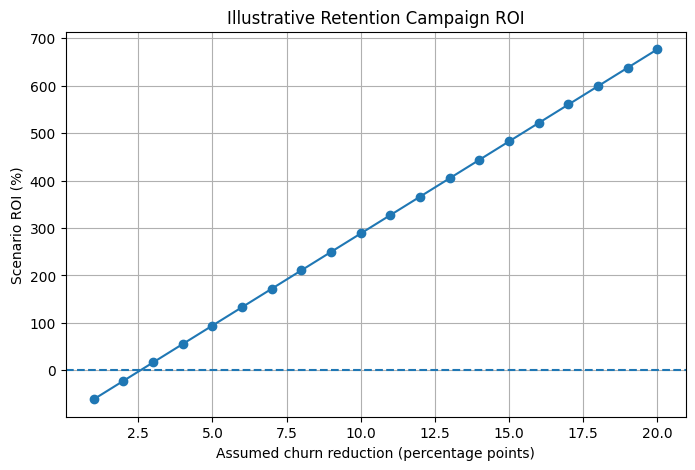

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

reductions = np.arange(0.01, 0.201, 0.01)
retained = customers_slider.value * reductions
preserved = retained * months_slider.value * average_monthly_charges
campaign_cost = customers_slider.value * cost_slider.value
rois = (preserved - campaign_cost) / campaign_cost * 100

plt.figure(figsize=(8, 5))
plt.plot(reductions * 100, rois, marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Assumed churn reduction (percentage points)")
plt.ylabel("Scenario ROI (%)")
plt.title("Illustrative Retention Campaign ROI")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

reductions = np.arange(0.01, 0.201, 0.01)
retained = customers_slider.value * reductions
preserved = retained * months_slider.value * average_monthly_charges
campaign_cost = customers_slider.value * cost_slider.value
rois = (preserved - campaign_cost) / campaign_cost * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(reductions * 100, rois, marker="o")
ax.axhline(0, linestyle="--")
ax.set_xlabel("Assumed churn reduction (percentage points)")
ax.set_ylabel("Scenario ROI (%)")
ax.set_title("Illustrative Retention Campaign ROI")
ax.grid(True)

fig.savefig(
    "/content/retention_roi_sensitivity.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(fig)

from google.colab import files
files.download("/content/retention_roi_sensitivity.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("retention_roi_sensitivity.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.preprocessing import StandardScaler

cluster_features = df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
cluster_features = cluster_features.astype(float)

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(cluster_features)

print("Clustering data prepared:", X_cluster_scaled.shape)

Clustering data prepared: (7043, 3)


In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean["CustomerCluster"] = kmeans.fit_predict(X_cluster_scaled)

print(df_clean["CustomerCluster"].value_counts().sort_index())

CustomerCluster
0    2154
1    2200
2    2689
Name: count, dtype: int64


In [ ]:
cluster_profile = df_clean.groupby("CustomerCluster").agg(
    Customers=("Churn", "size"),
    AvgTenure=("tenure", "mean"),
    AvgMonthlyCharges=("MonthlyCharges", "mean"),
    ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
).round(2)

display(cluster_profile)

,Customers,AvgTenure,AvgMonthlyCharges,ChurnRate
CustomerCluster,,,,
0,2154,29.50,26.57,12.30
1,2200,58.56,89.70,15.36
2,2689,13.25,74.95,47.08


In [ ]:
cluster_profile.to_csv("customer_cluster_profile.csv")
print("Saved customer_cluster_profile.csv")

Saved customer_cluster_profile.csv


In [ ]:
import os

files_to_check = [
    "lightgbm_churn_model.pkl",
    "shap_feature_importance.csv",
    "retention_roi_scenario.csv",
    "retention_roi_sensitivity.png",
    "customer_cluster_profile.csv",
]

for filename in files_to_check:
    print(f"{filename}: {'Saved' if os.path.exists(filename) else 'Not found'}")

lightgbm_churn_model.pkl: Saved
shap_feature_importance.csv: Saved
retention_roi_scenario.csv: Saved
retention_roi_sensitivity.png: Saved
customer_cluster_profile.csv: Saved


In [ ]:
%pip install -q causalml

In [ ]:
from causalml.inference.meta import BaseSClassifier
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

model = BaseSClassifier(
    learner=RandomForestClassifier(
        n_estimators=40,
        max_depth=8,
        min_samples_leaf=30,
        random_state=42,
        n_jobs=2
    )
)

model.fit(X=X, treatment=treatment, y=y)
uplift = np.asarray(model.predict(X=X)).reshape(-1)

print("Model fit and prediction completed.")

NameError: name 'treatment' is not defined

In [ ]:
uplift_output = pd.DataFrame({
    "customerID": df_clean.index.astype(str),
    "uplift_score": uplift,
    "predicted_churn_reduction": -uplift
})

uplift_output.to_csv("/content/customer_uplift_scores.csv", index=False)

print("Saved:", "/content/customer_uplift_scores.csv")
display(uplift_output.head(10))

NameError: name 'uplift' is not defined

In [ ]:
pip install lifelines

In [ ]:
import lifelines
print(lifelines.__version__)

Customers used: 7,043
Observed churn events: 1,869


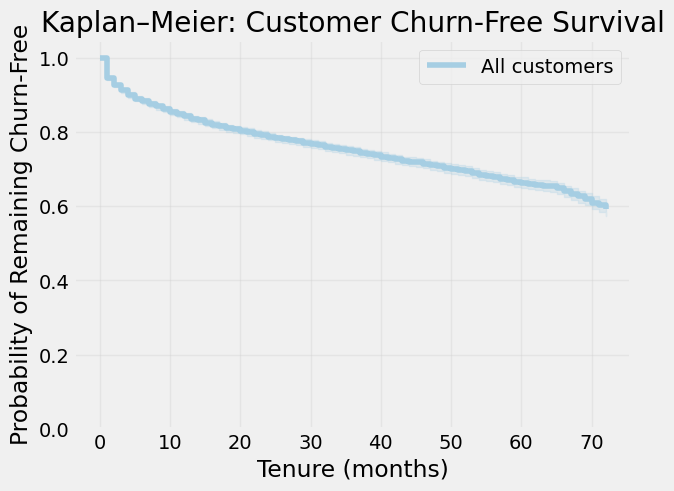

,Month,Churn-free survival probability
0,12,0.843200
1,24,0.788736


Rows used for Cox model: 7,032
Cox predictors: ['SeniorCitizen', 'MonthlyCharges', 'Partner_Yes', 'Dependents_Yes', 'Contract_One year', 'Contract_Two year', 'InternetService_Fiber optic', 'InternetService_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,Feature,Hazard ratio,HR 95% lower,HR 95% upper,p-value
0,SeniorCitizen,0.9128,0.8193,1.0170,0.0982
1,MonthlyCharges,0.9838,0.9802,0.9874,0.0000
2,Partner_Yes,0.5804,0.5231,0.6439,0.0000
3,Dependents_Yes,0.9180,0.8069,1.0444,0.1937
4,Contract_One year,0.2227,0.1904,0.2606,0.0000
5,Contract_Two year,0.0742,0.0587,0.0937,0.0000
6,InternetService_Fiber optic,2.2776,1.9106,2.7150,0.0000
7,InternetService_No,0.6549,0.4093,1.0478,0.0775
8,TechSupport_No internet service,0.6549,0.4093,1.0478,0.0775
9,TechSupport_Yes,0.6815,0.6007,0.7732,0.0000


Cox model concordance index: 0.8552


,Metric,Value
0,Concordance index,0.855234
1,Rows used,7032.000000
2,Churn events,1869.000000


Saved: kaplan_meier_survival.csv
Saved: kaplan_meier_estimates.csv
Saved: cox_model_results.csv
Saved: cox_model_summary.csv


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from IPython.display import display

survival_df = df.copy()
survival_df.columns = survival_df.columns.str.strip()

# Find columns without depending on capitalization
col_map = {col.lower(): col for col in survival_df.columns}
tenure_col = col_map.get("tenure")
churn_col = col_map.get("churn")

if tenure_col is None or churn_col is None:
    raise ValueError(
        "Required columns not found. Available columns: "
        + ", ".join(survival_df.columns)
    )

survival_df["duration"] = pd.to_numeric(
    survival_df[tenure_col], errors="coerce"
)

survival_df["event"] = (
    survival_df[churn_col]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1", "churned"])
    .astype(int)
)

survival_df = survival_df.dropna(subset=["duration"])
survival_df = survival_df[survival_df["duration"] >= 0].copy()

print(f"Customers used: {len(survival_df):,}")
print(f"Observed churn events: {survival_df['event'].sum():,}")

kmf = KaplanMeierFitter()
kmf.fit(
    durations=survival_df["duration"],
    event_observed=survival_df["event"],
    label="All customers"
)

ax = kmf.plot_survival_function()
ax.set_title("Kaplan–Meier: Customer Churn-Free Survival")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Probability of Remaining Churn-Free")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
plt.show()

# Survival probability at 12 and 24 months
km_estimates = pd.DataFrame({
    "Month": [12, 24],
    "Churn-free survival probability": [
        float(kmf.predict(12)),
        float(kmf.predict(24))
    ]
})
display(km_estimates)

# Export the Kaplan–Meier curve
km_curve = kmf.survival_function_.reset_index()
km_curve.columns = ["tenure_months", "survival_probability"]
km_curve.to_csv("kaplan_meier_survival.csv", index=False)


km_estimates.to_csv("kaplan_meier_estimates.csv", index=False)


candidate_features = [
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "MonthlyCharges",
    "Contract",
    "InternetService",
    "TechSupport",
    "OnlineSecurity",
    "PaymentMethod"
]

actual_columns = {col.lower(): col for col in survival_df.columns}
feature_cols = [
    actual_columns[name.lower()]
    for name in candidate_features
    if name.lower() in actual_columns
]

if not feature_cols:
    raise ValueError(
        "No candidate Cox predictors found. Check the dataset column names."
    )

cox_df = survival_df[["duration", "event"] + feature_cols].copy()

for col in feature_cols:
    if pd.api.types.is_numeric_dtype(cox_df[col]):
        cox_df[col] = pd.to_numeric(cox_df[col], errors="coerce")
    else:
        cox_df[col] = cox_df[col].astype("string").fillna("Unknown")

cox_df = cox_df.dropna(subset=["duration", "event"])
cox_df = cox_df[cox_df["duration"] > 0].copy()

categorical_cols = [
    col for col in feature_cols
    if not pd.api.types.is_numeric_dtype(cox_df[col])
]

cox_df = pd.get_dummies(
    cox_df,
    columns=categorical_cols,
    drop_first=True,
    dtype=float
)

for col in cox_df.columns:
    cox_df[col] = pd.to_numeric(cox_df[col], errors="coerce")

cox_df = cox_df.dropna()

predictors = [
    col for col in cox_df.columns
    if col not in ["duration", "event"] and cox_df[col].nunique() > 1
]

cox_df = cox_df[["duration", "event"] + predictors]

if not predictors:
    raise ValueError("No usable Cox predictors remain after cleaning.")

print(f"Rows used for Cox model: {len(cox_df):,}")
print("Cox predictors:", predictors)

cph = CoxPHFitter(penalizer=0.01)
cph.fit(
    cox_df,
    duration_col="duration",
    event_col="event"
)

cox_results = cph.summary.reset_index()
cox_results = cox_results.rename(columns={
    "covariate": "Feature",
    "exp(coef)": "Hazard ratio",
    "exp(coef) lower 95%": "HR 95% lower",
    "exp(coef) upper 95%": "HR 95% upper",
    "p": "p-value"
})

display_cols = [
    col for col in [
        "Feature",
        "Hazard ratio",
        "HR 95% lower",
        "HR 95% upper",
        "p-value"
    ]
    if col in cox_results.columns
]

display(cox_results[display_cols].round(4))

print(f"Cox model concordance index: {cph.concordance_index_:.4f}")
cox_results.to_csv("cox_model_results.csv", index=False)

cox_model_summary = pd.DataFrame({
    "Metric": ["Concordance index", "Rows used", "Churn events"],
    "Value": [
        float(cph.concordance_index_),
        int(len(cox_df)),
        int(cox_df["event"].sum())
    ]
})

display(cox_model_summary)
cox_model_summary.to_csv("cox_model_summary.csv", index=False)

print("Saved: kaplan_meier_survival.csv")
print("Saved: kaplan_meier_estimates.csv")
print("Saved: cox_model_results.csv")
print("Saved: cox_model_summary.csv")

In [ ]:
from google.colab import files

files.download("kaplan_meier_survival.csv")
files.download("cox_model_results.csv")
files.download("cox_model_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Find existing uplift-related variables and dataframes in the notebook
for name, obj in globals().copy().items():
    if any(term in name.lower() for term in ["uplift", "causal", "treatment", "effect"]):
        print(name, type(obj).__name__, getattr(obj, "shape", ""))

In [ ]:
print("uplift_df columns:", uplift_df.columns.tolist())
display(uplift_df.head(3))

print("uplift_output columns:", uplift_output.columns.tolist())
display(uplift_output.head(5))

print("uplift shape:", uplift.shape)
print("treatment shape:", treatment.shape)

NameError: name 'uplift_df' is not defined

In [ ]:
import numpy as np
import pandas as pd
customer_uplift_scores = pd.DataFrame({
    "customerID": uplift_df["customerID"].astype(str).to_numpy(),
    "uplift_score": pd.to_numeric(uplift_output["uplift_score"], errors="coerce").to_numpy(),
    "predicted_churn_reduction": pd.to_numeric(
        uplift_output["predicted_churn_reduction"], errors="coerce"
    ).to_numpy()
})

customer_uplift_scores["uplift_rank"] = (
    customer_uplift_scores["uplift_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

customer_uplift_scores["recommended_action"] = np.where(
    customer_uplift_scores["uplift_score"] > 0,
    "Prioritize for retention offer",
    "Do not prioritize based on uplift"
)

customer_uplift_scores.to_csv("customer_uplift_scores.csv", index=False)

display(customer_uplift_scores.head(10))
print("Saved customer_uplift_scores.csv")


In [ ]:
print("treatment:", type(treatment), getattr(treatment, "shape", None))
print("treatment values/counts:", pd.Series(treatment).value_counts(dropna=False).to_dict())

print("y:", type(y), getattr(y, "shape", None))
print("y values/counts:", pd.Series(y).value_counts(dropna=False).to_dict())

print("X:", type(X), getattr(X, "shape", None))

In [ ]:
import numpy as np
import pandas as pd

print("Treatment values:", np.unique(treatment))
print("Treatment by churn:")
print(pd.crosstab(treatment, y, rownames=["treatment"], colnames=["churn"]))

print("\nX columns sample:")
print(list(X.columns[:30]))

In [ ]:
# Show whether treatment was created from a real assignment field
print("Original dataframe columns:")
print(df_clean.columns.tolist())

# Check if treatment is in the dataframe and compare it to possible source columns
for col in df_clean.columns:
    if "treat" in col.lower() or "offer" in col.lower() or "campaign" in col.lower():
        print("\nCandidate:", col)
        print(pd.crosstab(df_clean[col], treatment))

Original dataframe columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'CustomerCluster']


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": (final_model, X_test_final),
    "LightGBM": (lgbm_model, X_test),
    "Random Forest": (rf_model, X_test),
}

rows = []

for name, (model, features) in models.items():
    probs = model.predict_proba(features)[:, 1]
    preds = (probs >= 0.5).astype(int)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probs),
    })

pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,LightGBM,0.757,0.530,0.727,0.613,0.834
2,Random Forest,0.779,0.603,0.484,0.537,0.823


In [ ]:
print(X_encoded.shape)
print(X_encoded.columns.tolist())

In [ ]:
# Confirm the feature order matches what LightGBM was trained on
print("Model expects:", lgbm_model.n_features_in_)
print("Input features:", X_encoded.shape[1])

# Generate churn probabilities for all customers
churn_probabilities = lgbm_model.predict_proba(X_encoded)[:, 1]

# Build customer-level predictions
churn_predictions = pd.DataFrame({
    "customerID": df["customerID"].astype(str).to_numpy(),
    "churn_probability": churn_probabilities
})

churn_predictions["risk_level"] = pd.cut(
    churn_predictions["churn_probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)

# Save and inspect
churn_predictions.to_csv("churn_predictions.csv", index=False)
display(churn_predictions.sort_values("churn_probability", ascending=False).head(10))

Model expects: 40
Input features: 40


,customerID,churn_probability,risk_level
4517,2012-NWRPA,0.990186,High
2831,2454-RPBRZ,0.986666,High
2631,6861-XWTWQ,0.985909,High
2208,7216-EWTRS,0.985779,High
1704,0107-YHINA,0.985698,High
3610,2612-RANWT,0.985217,High
3349,0897-FEGMU,0.985013,High
6623,9248-OJYKK,0.984315,High
39,8168-UQWWF,0.983643,High
7032,6894-LFHLY,0.983543,High


In [ ]:
# Join predicted risk with the original customer characteristics
customer_risk = df.merge(
    churn_predictions[["customerID", "churn_probability", "risk_level"]],
    on="customerID",
    how="left"
)

# Sort highest risk first and show useful profile fields
display_cols = [
    "customerID", "churn_probability", "risk_level",
    "tenure", "Contract", "MonthlyCharges",
    "InternetService", "OnlineSecurity", "TechSupport", "PaymentMethod"
]

display(
    customer_risk[display_cols]
    .sort_values("churn_probability", ascending=False)
    .head(20)
)

customer_risk.to_csv("customer_churn_risk.csv", index=False)

,customerID,churn_probability,risk_level,tenure,Contract,MonthlyCharges,InternetService,OnlineSecurity,TechSupport,PaymentMethod
4517,2012-NWRPA,0.990186,High,11,Month-to-month,99.55,Fiber optic,No,No,Electronic check
2831,2454-RPBRZ,0.986666,High,12,Month-to-month,98.10,Fiber optic,No,No,Electronic check
2631,6861-XWTWQ,0.985909,High,7,Month-to-month,99.25,Fiber optic,No,No,Electronic check
2208,7216-EWTRS,0.985779,High,1,Month-to-month,100.80,Fiber optic,No,No,Electronic check
1704,0107-YHINA,0.985698,High,1,Month-to-month,99.75,Fiber optic,No,No,Electronic check
3610,2612-RANWT,0.985217,High,12,Month-to-month,100.15,Fiber optic,No,No,Bank transfer (automatic)
3349,0897-FEGMU,0.985013,High,11,Month-to-month,99.50,Fiber optic,No,No,Electronic check
6623,9248-OJYKK,0.984315,High,1,Month-to-month,76.45,Fiber optic,No,No,Electronic check
39,8168-UQWWF,0.983643,High,11,Month-to-month,97.85,Fiber optic,No,No,Bank transfer (automatic)
7032,6894-LFHLY,0.983543,High,1,Month-to-month,75.75,Fiber optic,No,No,Electronic check


In [ ]:
def contact_focus(row):
    focus = []

    if row["tenure"] <= 12:
        focus.append("New-customer check-in")
    if row["Contract"] == "Month-to-month":
        focus.append("Review contract options")
    if row["MonthlyCharges"] >= 90:
        focus.append("Review bill and plan fit")
    if row["OnlineSecurity"] == "No":
        focus.append("Discuss online security")
    if row["TechSupport"] == "No":
        focus.append("Discuss tech support")

    return "; ".join(focus) if focus else "General account check-in"

customer_risk["contact_focus"] = customer_risk.apply(contact_focus, axis=1)

customer_risk = customer_risk.sort_values(
    "churn_probability", ascending=False
)

customer_risk.to_csv("customer_churn_risk.csv", index=False)

display(customer_risk[
    ["customerID", "churn_probability", "risk_level", "contact_focus"]
].head(20))

,customerID,churn_probability,risk_level,contact_focus
4517,2012-NWRPA,0.990186,High,New-customer check-in; Review contract options...
2831,2454-RPBRZ,0.986666,High,New-customer check-in; Review contract options...
2631,6861-XWTWQ,0.985909,High,New-customer check-in; Review contract options...
2208,7216-EWTRS,0.985779,High,New-customer check-in; Review contract options...
1704,0107-YHINA,0.985698,High,New-customer check-in; Review contract options...
3610,2612-RANWT,0.985217,High,New-customer check-in; Review contract options...
3349,0897-FEGMU,0.985013,High,New-customer check-in; Review contract options...
6623,9248-OJYKK,0.984315,High,New-customer check-in; Review contract options...
39,8168-UQWWF,0.983643,High,New-customer check-in; Review contract options...
7032,6894-LFHLY,0.983543,High,New-customer check-in; Review contract options...


In [ ]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nChurn values:")
print(df["Churn"].value_counts(dropna=False))
print("\nTenure summary:")
print(df["tenure"].describe())

Shape: (7043, 22)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Encoded']

Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Tenure summary:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


In [ ]:
print("Missing tenure:", df["tenure"].isna().sum())
print("Missing churn:", df["Churn"].isna().sum())
print("Negative tenure:", (df["tenure"] < 0).sum())
print("Churn labels:", sorted(df["Churn"].dropna().unique()))

Missing tenure: 0
Missing churn: 0
Negative tenure: 0
Churn labels: ['No', 'Yes']


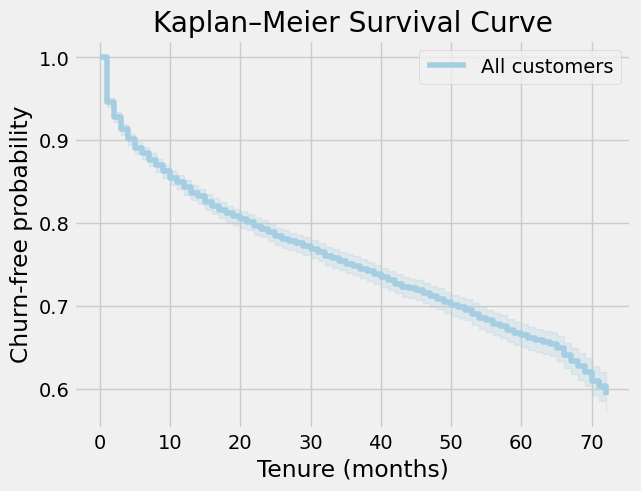

12-month churn-free estimate: 84.32%
24-month churn-free estimate: 78.87%


In [ ]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

km_df = df[["tenure", "Churn"]].copy()
km_df["event"] = km_df["Churn"].eq("Yes").astype(int)

kmf = KaplanMeierFitter()
kmf.fit(
    durations=km_df["tenure"],
    event_observed=km_df["event"],
    label="All customers"
)

kmf.plot_survival_function()
plt.xlabel("Tenure (months)")
plt.ylabel("Churn-free probability")
plt.title("Kaplan–Meier Survival Curve")
plt.grid(True)
plt.show()

print(f"12-month churn-free estimate: {kmf.predict(12):.2%}")
print(f"24-month churn-free estimate: {kmf.predict(24):.2%}")

In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use the existing trained models and the same test dataset
threshold = 0.40

# Logistic Regression predictions
lr_probabilities = final_model.predict_proba(X_test_final)[:, 1]
lr_predictions = (lr_probabilities >= threshold).astype(int)

# LightGBM predictions
lgbm_probabilities = lgbm_model.predict_proba(X_test)[:, 1]
lgbm_predictions = (lgbm_probabilities >= threshold).astype(int)

# ---------- 1. Model evaluation ----------
evaluation_rows = []

for name, predictions in [
    ("Logistic Regression", lr_predictions),
    ("LightGBM", lgbm_predictions)
]:
    evaluation_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1_Score": f1_score(y_test, predictions, zero_division=0)
    })

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation.to_csv("model_evaluation.csv", index=False)

# ---------- 2. Confusion matrix ----------
confusion_rows = []

for name, predictions in [
    ("Logistic Regression", lr_predictions),
    ("LightGBM", lgbm_predictions)
]:
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    confusion_rows.append({
        "Model": name,
        "True_Negatives": tn,
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp
    })

confusion_results = pd.DataFrame(confusion_rows)
confusion_results.to_csv("confusion_matrix.csv", index=False)

# ---------- Display and verify ----------
print("MODEL EVALUATION")
display(model_evaluation.round(4))

print("CONFUSION MATRIX")
display(confusion_results)

print("Both CSV files saved successfully.")


MODEL EVALUATION


,Model,Threshold,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.4,0.7771,0.5682,0.6684,0.6143
1,LightGBM,0.4,0.7339,0.4992,0.7888,0.6114


CONFUSION MATRIX


,Model,True_Negatives,False_Positives,False_Negatives,True_Positives
0,Logistic Regression,845,190,124,250
1,LightGBM,739,296,79,295


Both CSV files saved successfully.


In [ ]:
from google.colab import files

files.download("model_evaluation.csv")
files.download("confusion_matrix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>